## Project Overview

This project implements an object detection system using the YOLOv2 (You Only Look Once) algorithm with pre-trained COCO weights. It detects and classifies objects belonging to 80 different categories in input images, generating bounding boxes along with corresponding confidence scores.

## Methodology

<b>1) Pre-trained Model:</b> Uses YOLOv2 with COCO weights to detect objects across 80 different classes.

<b>2) Object Detection:</b> Processes input images to identify objects and predict their corresponding bounding box coordinates and confidence scores.

<b>3) Non-Maximum Suppression (NMS):</b> Eliminates duplicate and overlapping bounding boxes by retaining the most confident detection for each object.

<b>4) Visualization:</b> Uses Matplotlib to display detected objects with their bounding boxes, class labels and confidence scores.

## Key Feature

The system performs real-time-style object detection on images, identifying multiple object categories and filtering redundant detections using Non-Maximum Suppression.

In [1]:
import numpy as np 
import tensorflow as tf 
import matplotlib.pyplot as plt 
from matplotlib.patches import Rectangle 
from PIL import Image 
from tensorflow.keras import layers

In [2]:
model_image_size = 608     
num_classes = 80           # COCO classes 
# the 5 anchor boxes (width, height)
anchors = np.array([[0.57273, 0.677385], [1.87446, 2.06253], [3.33843, 5.47434],                    
                    [7.88282, 3.52778], [9.77052, 9.16828]], dtype=np.float32) 
class_names = ["person", "bicycle", "car", "motorbike", "aeroplane", "bus", "train", "truck",    "boat", "traffic light", "fire hydrant", "stop sign", "parking meter", "bench", "bird",    "cat", "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra", "giraffe", "backpack",    "umbrella", "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard", "sports ball",    "kite", "baseball bat", "baseball glove", "skateboard", "surfboard", "tennis racket",    "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair",    "sofa", "pottedplant", "bed", "diningtable", "toilet", "tvmonitor", "laptop", "mouse",    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator",    "book", "clock", "vase", "scissors", "teddy bear", "hair drier", "toothbrush"]

In [3]:
def build_yolo():       
    blocks = []    
    def conv_block(x, filters, size):        
        conv = layers.Conv2D(filters, size, padding="same", use_bias=False)        
        bn = layers.BatchNormalization()        
        blocks.append((conv, bn))        
        return layers.LeakyReLU(0.1)(bn(conv(x)))    
    inputs = layers.Input((model_image_size, model_image_size, 3))    
    x = conv_block(inputs, 32, 3)    
    x = layers.MaxPooling2D(2)(x)    
    x = conv_block(x, 64, 3)    
    x = layers.MaxPooling2D(2)(x)    
    for filters, size in [(128, 3), (64, 1), (128, 3)]:        
        x = conv_block(x, filters, size)    
    x = layers.MaxPooling2D(2)(x)    
    for filters, size in [(256, 3), (128, 1), (256, 3)]:       
        x = conv_block(x, filters, size)    
    x = layers.MaxPooling2D(2)(x)    
    for filters, size in [(512, 3), (256, 1), (512, 3), (256, 1), (512, 3)]:        
        x = conv_block(x, filters, size)    
    skip = x                                               
    x = layers.MaxPooling2D(2)(x)    
    for filters, size in [(1024, 3), (512, 1), (1024, 3), (512, 1),                          
                          (1024, 3), (1024, 3), (1024, 3)]:        
        x = conv_block(x, filters, size)    
    # passthrough: bring the finer 38x38 features down to 19x19 and join them    
    skip = conv_block(skip, 64, 1)    
    skip = layers.Lambda(lambda t: tf.nn.space_to_depth(t, 2))(skip)       
    x = layers.concatenate([skip, x])                                     
    x = conv_block(x, 1024, 3)    
    last = layers.Conv2D(len(anchors) * (num_classes + 5), 1, padding="same")    
    blocks.append((last, None))    
    return tf.keras.Model(inputs, last(x)), blocks          
yolo_model, blocks = build_yolo()

In [4]:
def load_darknet_weights(model, blocks, weights_path):    
    """Copies the weights of the official yolov2.weights file into the model."""    
    data = np.fromfile(weights_path, dtype=np.float32)    
    data = data[len(data) - model.count_params():]          
    pos = 0    
    def read(n):        
        nonlocal pos        
        pos += n        
        return data[pos - n:pos]    
    for conv, bn in blocks:        
        k_h, k_w, c_in, c_out = conv.get_weights()[0].shape        
        if bn is not None:            
            beta, gamma, mean, var = read(4 * c_out).reshape(4, c_out)        
        else:            
            bias = read(c_out)               
        kernel = read(c_out * c_in * k_h * k_w).reshape(c_out, c_in, k_h, k_w)        
        kernel = kernel.transpose(2, 3, 1, 0)        
        if bn is not None:            
            conv.set_weights([kernel])            
            bn.set_weights([gamma, beta, mean, var])        
        else:            
            conv.set_weights([kernel, bias]) 
load_darknet_weights(yolo_model, blocks, "yolov2.weights")

In [5]:
def yolo_head(feats):        
    n_H, n_W = feats.shape[1:3]    
    feats = tf.reshape(feats, [-1, n_H, n_W, len(anchors), num_classes + 5])      
    grid_y, grid_x = tf.meshgrid(tf.range(n_H), tf.range(n_W), indexing="ij")    
    grid = tf.cast(tf.stack([grid_x, grid_y], axis=-1), tf.float32)[:, :, tf.newaxis, :]    
    grid_size = tf.constant([n_W, n_H], dtype=tf.float32)    
    box_xy = (tf.sigmoid(feats[..., 0:2]) + grid) / grid_size    
    box_wh = tf.exp(feats[..., 2:4]) * anchors / grid_size    
    box_confidence = tf.sigmoid(feats[..., 4:5])    
    box_class_probs = tf.nn.softmax(feats[..., 5:])    
    return box_xy, box_wh, box_confidence, box_class_probs

In [6]:
def yolo_filter_boxes(boxes, box_confidence, box_class_probs, threshold=.3):    
    """Keeps only the boxes whose best class score is >= threshold."""       
    box_scores = box_confidence * box_class_probs        
    box_classes = tf.math.argmax(box_scores, axis=-1)    
    box_class_scores = tf.math.reduce_max(box_scores, axis=-1)        
    filtering_mask = box_class_scores >= threshold        
    scores = tf.boolean_mask(box_class_scores, filtering_mask)    
    boxes = tf.boolean_mask(boxes, filtering_mask)    
    classes = tf.boolean_mask(box_classes, filtering_mask)    
    return scores, boxes, classes

In [7]:
def yolo_non_max_suppression(scores, boxes, classes, max_boxes=10, iou_threshold=.5):        
    nms_indices = [tf.zeros([0], dtype=tf.int64)]    
    for label in tf.unique(classes)[0]:              
        label_indices = tf.squeeze(tf.where(tf.equal(classes, label)), axis=1)        
        keep = tf.image.non_max_suppression(tf.gather(boxes, label_indices),                                            
                                            tf.gather(scores, label_indices),                                            
                                            max_output_size=max_boxes,                                            
                                            iou_threshold=iou_threshold)        
        nms_indices.append(tf.gather(label_indices, keep))    
    nms_indices = tf.concat(nms_indices, axis=0)    
    scores = tf.gather(scores, nms_indices)    
    boxes = tf.gather(boxes, nms_indices)    
    classes = tf.gather(classes, nms_indices)       
    order = tf.argsort(scores, direction="DESCENDING")[:max_boxes]    
    return tf.gather(scores, order), tf.gather(boxes, order), tf.gather(classes, order)

In [8]:
def yolo_boxes_to_corners(box_xy, box_wh):      
    box_mins = box_xy - box_wh / 2.    
    box_maxes = box_xy + box_wh / 2.    
    return tf.concat([box_mins[..., ::-1], box_maxes[..., ::-1]], axis=-1) 

def yolo_eval(yolo_outputs, image_shape, max_boxes=10, score_threshold=.3, iou_threshold=.5):      
    box_xy, box_wh, box_confidence, box_class_probs = yolo_outputs       
    boxes = yolo_boxes_to_corners(box_xy, box_wh)      
    scores, boxes, classes = yolo_filter_boxes(boxes, box_confidence, box_class_probs,                                               
                                               score_threshold)     
    height, width = image_shape    
    boxes = boxes * tf.constant([height, width, height, width], dtype=tf.float32)     
    return yolo_non_max_suppression(scores, boxes, classes, max_boxes, iou_threshold)

In [9]:
def predict(image_path):    
    """Detects the objects in image_path, prints them and draws the boxes."""    
    image = Image.open(image_path).convert("RGB")    
    x = image.resize((model_image_size, model_image_size), Image.BICUBIC)    
    x = np.array(x, dtype=np.float32)[np.newaxis] / 255.0            
    yolo_outputs = yolo_head(yolo_model(x))    
    out_scores, out_boxes, out_classes = yolo_eval(yolo_outputs, (image.height, image.width))    
    print("Found {} boxes for {}".format(len(out_boxes), image_path))    
    fig, ax = plt.subplots(figsize=(10, 6))    
    ax.imshow(image)    
    for score, (y1, x1, y2, x2), c in zip(out_scores.numpy(), out_boxes.numpy(),                                          
                                          out_classes.numpy()):        
        label = "{} {:.2f}".format(class_names[c], score)        
        print(label, (int(x1), int(y1)), (int(x2), int(y2)))        
        color = plt.cm.hsv(c / num_classes)  # one colour per class        
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,                               
                               edgecolor=color, linewidth=2))        
        ax.text(x1, y1 - 4, label, color="black", backgroundcolor=color, fontsize=8)    
    ax.axis("off")    
    plt.show()    
    return out_scores, out_boxes, out_classes

Found 8 boxes for test1.jpeg
truck 0.84 (-2, 260) (492, 804)
car 0.65 (1112, 479) (1281, 686)
motorbike 0.60 (968, 521) (1108, 618)
motorbike 0.52 (713, 476) (776, 564)
person 0.49 (717, 452) (779, 546)
person 0.49 (981, 462) (1095, 610)
person 0.41 (610, 458) (632, 505)
person 0.38 (218, 348) (290, 426)


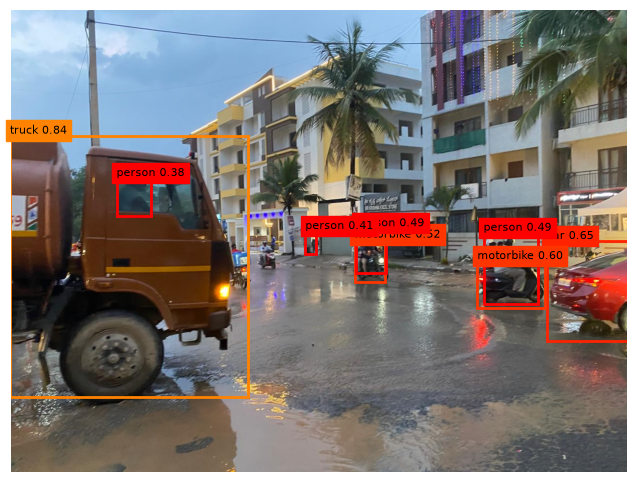

In [10]:
out_scores, out_boxes, out_classes = predict("test1.jpeg")